# Лабораторная работа № 2. Марковские модели систем массового обслуживания

**Моделирование · вариант 16/16/13**  
Якименко Владислав Игоревич · P3313  
Преподаватель: Авксентьева Елена Юрьевна

**Цель:** построить марковские модели двух СМО, рассчитать стационарные вероятности
и характеристики и выбрать систему с максимальной производительностью.

Порядок: исходные условия → фазы обслуживания → состояния и переходы → матрицы
интенсивностей → стационарные вероятности → характеристики → проверка → сравнение.

Notebook самостоятельно строит и решает обе модели. Excel читается только в конце
для сверки. Это **расчёт Python**: обязательный по п. 4.3 методички ручной этап MARK
ещё нужно выполнить; notebook не является выгрузкой WinMark.

## Как запустить

Открыть notebook в VS Code или JupyterLab. Установить зависимости командой
`python -m pip install -r requirements.txt`. В VS Code на этом компьютере выбрать
**Python (ITMO Modeling 3.12)** и нажать **Run All**.

Ячейки выполняются сверху вниз: состояние ядра хранит импортированные библиотеки,
функции и результаты предыдущих шагов. Все результаты выполнения уже сохранены.
Для расчёта готовая книга Excel не нужна; без неё пропускается заключительная сверка.

In [1]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import openpyxl
from IPython.display import display, Markdown

BLUE, GREEN, RED = "#245581", "#28714d", "#d34b2a"
plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 10,
                     "figure.figsize": (9, 3.3)})


def show_table(frame, index=True, digits=6):
    if frame.index.nlevels > 1:
        frame, index = frame.reset_index(), False
    display(Markdown(frame.to_markdown(index=index, floatfmt=f".{digits}f")))

## 1. Исходные условия и критерий

Параметры соответствуют принятому варианту **16/16/13** и таблицам 1–2 методички.
$NG=13$ — две последние цифры группы; $N1$ и $N2$ задают структурные варианты,
а не вычисляются из группы. Так как $16+16$ чётно, критерий берётся по $N2$:
**максимальная производительность**.

| Параметр | СИСТЕМА_1 | СИСТЕМА_2 |
|---|---|---|
| Приборы | 3, все экспоненциальные | 2; П1 — $H_{2.5}$, П2 — экспоненциальный |
| Очереди по заданию | 1/1/0 | 2/2 |
| Очереди в расчёте | 1/1/0 | 1/2 |
| Входной поток | $\lambda=0.8$ заявки/с | то же |
| Среднее обслуживание | $b=5$ с | то же |
| Маршрутизация | 0.30 / 0.45 / 0.25 | 0.30 / 0.70 |

При двух приборах вторая вероятность равна $0.45+0.25=0.70$ по указанию методички.
Заявка сразу выбирает ветвь. Если там нет места, она теряется; перенаправления нет.
Дисциплина очередей — FIFO. Одна обслуживаемая заявка **не входит** в ёмкость очереди.

$$\lambda_j=\lambda\alpha_j,\qquad\mu=\frac1b.$$

In [2]:
N1, N2, NG = 16, 16, 13
BASE_LAMBDA = 0.8
B = 5.0
MU = 1 / B
ALPHA1 = np.array([0.30, 0.45, 0.25])
ALPHA2 = np.array([0.30, 0.70])
CV_H = 2.5
CAPACITY1 = np.array([2, 2, 1])  # Вместимость: очередь + прибор.
CAPACITY2 = np.array([2, 3])
assert B > 0 and BASE_LAMBDA > 0 and CV_H > 1
np.testing.assert_allclose([ALPHA1.sum(), ALPHA2.sum()], [1, 1])

show_table(pd.DataFrame({"Система": ["СИСТЕМА_1", "СИСТЕМА_2"],
                        "Интенсивности по ветвям": [str(BASE_LAMBDA*ALPHA1), str(BASE_LAMBDA*ALPHA2)],
                        "Критерий": ["максимум производительности"]*2}), index=False)

| Система   | Интенсивности по ветвям   | Критерий                    |
|:----------|:--------------------------|:----------------------------|
| СИСТЕМА_1 | [0.24 0.36 0.2 ]          | максимум производительности |
| СИСТЕМА_2 | [0.24 0.56]               | максимум производительности |

## 2. Гиперэкспоненциальное обслуживание П1

Закон $H_{2.5}$ здесь **задан условием**. По известным $b$ и $\nu$ рассчитываются
параметры его фаз; подбирать закон по выборке из 300 измерений в этой работе не требуется.

Вторая система содержит один прибор с коэффициентом вариации $\nu=2.5>1$.
Используется смесь двух экспоненциальных законов со сбалансированными параметрами:

$$q=\frac12\left(1-\sqrt{\frac{\nu^2-1}{\nu^2+1}}\right),\qquad
\mu_a=\frac{2q}{b},\qquad\mu_b=\frac{2(1-q)}{b},$$
$$f_T(t)=q\mu_a e^{-\mu_at}+(1-q)\mu_b e^{-\mu_bt},\qquad t\geq0.$$

При начале обслуживания выбирается **одна** фаза: медленная $a$ с вероятностью $q$
или быстрая $b$ с вероятностью $1-q$. Две фазы не проходятся последовательно.

$$\mathrm M[T]=\frac q{\mu_a}+\frac{1-q}{\mu_b},\qquad
\mathrm D[T]=\frac{2q}{\mu_a^2}+\frac{2(1-q)}{\mu_b^2}-(\mathrm M[T])^2.$$

Знание текущей фазы позволяет описывать систему непрерывной марковской цепью:
остаточное время в каждой экспоненциальной фазе не зависит от её возраста.

|                      |   Значение |
|:---------------------|-----------:|
| q, медленная фаза    |   0.074519 |
| 1−q, быстрая фаза    |   0.925481 |
| μ_a, 1/с             |   0.029807 |
| μ_b, 1/с             |   0.370193 |
| Среднее T, с         |   5.000000 |
| Дисперсия T, с²      | 156.250000 |
| Коэффициент вариации |   2.500000 |

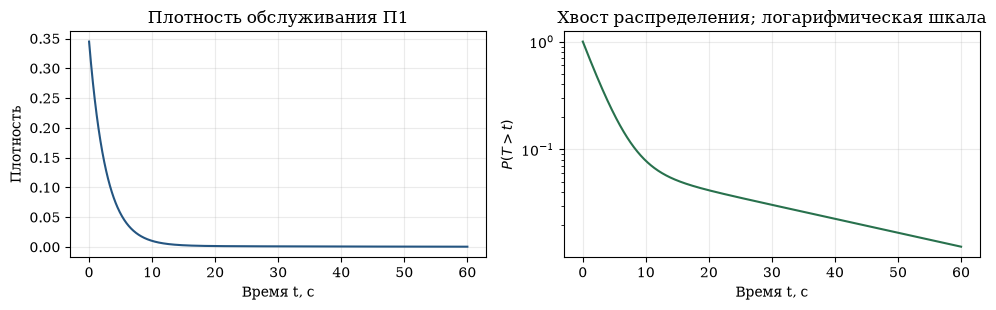

In [3]:
Q_SLOW = 0.5 * (1 - np.sqrt((CV_H**2 - 1) / (CV_H**2 + 1)))
MU_A = 2 * Q_SLOW / B
MU_B = 2 * (1-Q_SLOW) / B
h_mean = Q_SLOW/MU_A + (1-Q_SLOW)/MU_B
h_var = 2*Q_SLOW/MU_A**2 + 2*(1-Q_SLOW)/MU_B**2 - h_mean**2
np.testing.assert_allclose([h_mean, np.sqrt(h_var)/h_mean], [B, CV_H], rtol=1e-12)
show_table(pd.Series({"q, медленная фаза": Q_SLOW, "1−q, быстрая фаза": 1-Q_SLOW,
                      "μ_a, 1/с": MU_A, "μ_b, 1/с": MU_B,
                      "Среднее T, с": h_mean, "Дисперсия T, с²": h_var,
                      "Коэффициент вариации": np.sqrt(h_var)/h_mean}).to_frame("Значение"))

grid = np.linspace(0, 60, 1000)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(grid, Q_SLOW*MU_A*np.exp(-MU_A*grid) + (1-Q_SLOW)*MU_B*np.exp(-MU_B*grid), color=BLUE)
axes[0].set(xlabel="Время t, с", ylabel="Плотность", title="Плотность обслуживания П1")
axes[1].semilogy(grid, Q_SLOW*np.exp(-MU_A*grid)+(1-Q_SLOW)*np.exp(-MU_B*grid), color=GREEN)
axes[1].set(xlabel="Время t, с", ylabel=r"$P(T>t)$", title="Хвост распределения; логарифмическая шкала")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 3. Кодировка состояний

Первая система: $n_j$ — число заявок у прибора вместе с очередью.

$$\mathcal S_1=\{0,1,2\}\times\{0,1,2\}\times\{0,1\},\qquad|\mathcal S_1|=18.$$

Вторая система: $s_1\in\{0,1_a,1_b,2_a,2_b\}$, где цифра — число заявок у П1,
буква — фаза обслуживаемой заявки. У П2 $n_2\in\{0,1,2,3\}$.

$$\mathcal S_2=\{0,1_a,1_b,2_a,2_b\}\times\{0,1,2,3\},\qquad|\mathcal S_2|=20.$$

При исходных очередях 2/2 было бы $(1+2\cdot3)\cdot4=28$ состояний. На с. 7
методички допускается обоснованное минимальное уменьшение одного накопителя для
модели более чем с 20 состояниями. Поэтому очередь П1 сокращена с 2 до 1.
Это разрешение методички, а не технический предел WinMark. Сравнение ниже относится
к **сокращённой СИСТЕМЕ_2**.

In [4]:
states1 = list(product(range(3), range(3), range(2)))
states2 = list(product(["0", "1a", "1b", "2a", "2b"], range(4)))


def n_first(label):
    return 0 if label == "0" else int(label[0])


def occupancy(states, system):
    return np.array(states, dtype=int) if system == 1 else np.array(
        [[n_first(s1), n2] for s1, n2 in states])


def state_text(state):
    return "(" + ",".join(map(str, state)) + ")"


show_table(pd.DataFrame({"Система": ["СИСТЕМА_1", "СИСТЕМА_2"],
                        "Состояний": [len(states1), len(states2)],
                        "Первое состояние": [state_text(states1[0]), state_text(states2[0])],
                        "Последнее состояние": [state_text(states1[-1]), state_text(states2[-1])]}), index=False)

| Система   |   Состояний | Первое состояние   | Последнее состояние   |
|:----------|------------:|:-------------------|:----------------------|
| СИСТЕМА_1 |          18 | (0,0,0)            | (2,2,1)               |
| СИСТЕМА_2 |          20 | (0,0)              | (2b,3)                |

## 4. Переходы и матрицы интенсивностей

Строка матрицы — исходное состояние, столбец — следующее. Для $i\ne j$:

$$g_{ij}\geq0,\qquad g_{ii}=-\sum_{j\ne i}g_{ij},\qquad\sum_jg_{ij}=0.$$

В первой системе поступление увеличивает $n_j$ на один с интенсивностью $\lambda_j$,
завершение обслуживания уменьшает его с интенсивностью $\mu$ при $n_j>0$.
Прибор одноканальный: интенсивность обслуживания не умножается на число заявок.

Переходы П1 второй системы:

$$0\xrightarrow{\lambda_1q}1_a,\quad 0\xrightarrow{\lambda_1(1-q)}1_b,\qquad
1_a\xrightarrow{\lambda_1}2_a,\quad1_b\xrightarrow{\lambda_1}2_b,$$
$$1_\varphi\xrightarrow{\mu_\varphi}0,\quad
2_\varphi\xrightarrow{\mu_\varphi q}1_a,\quad
2_\varphi\xrightarrow{\mu_\varphi(1-q)}1_b.$$

При непустой очереди после завершения обслуживания выбирается новая фаза.
Потерянная заявка состояние не меняет; отдельный переход потери в $G$ не добавляется.

In [5]:
def make_generator(states, transition_rule):
    position = {state: i for i, state in enumerate(states)}
    matrix = np.zeros((len(states), len(states)))
    for state in states:
        i = position[state]
        for target, rate in transition_rule(state):
            assert target in position and target != state and rate >= 0
            matrix[i, position[target]] += rate
        matrix[i, i] = -matrix[i].sum()
    return matrix


def build_system1(lam):
    def transitions(state):
        edges = []
        for j, capacity in enumerate(CAPACITY1):
            if state[j] < capacity:
                target = list(state)
                target[j] += 1
                edges.append((tuple(target), lam*ALPHA1[j]))
            if state[j] > 0:
                target = list(state)
                target[j] -= 1
                edges.append((tuple(target), MU))
        return edges
    return make_generator(states1, transitions)

In [6]:
def build_system2(lam):
    def transitions(state):
        label, n2 = state
        n1 = n_first(label)
        edges = []
        if n1 == 0:
            edges += [(("1a", n2), lam*ALPHA2[0]*Q_SLOW),
                      (("1b", n2), lam*ALPHA2[0]*(1-Q_SLOW))]
        elif n1 < CAPACITY2[0]:
            edges.append(((f"{n1+1}{label[-1]}", n2), lam*ALPHA2[0]))

        if n1 > 0:
            rate = MU_A if label[-1] == "a" else MU_B
            if n1 == 1:
                edges.append((("0", n2), rate))
            else:
                edges += [(("1a", n2), rate*Q_SLOW),
                          (("1b", n2), rate*(1-Q_SLOW))]
        if n2 < CAPACITY2[1]:
            edges.append(((label, n2+1), lam*ALPHA2[1]))
        if n2 > 0:
            edges.append(((label, n2-1), MU))
        return edges
    return make_generator(states2, transitions)


G1, G2 = build_system1(BASE_LAMBDA), build_system2(BASE_LAMBDA)
print("Размеры матриц:", G1.shape, G2.shape)
print("Ненулевые внедиагональные переходы:", np.count_nonzero(G1 > 0), np.count_nonzero(G2 > 0))

Размеры матриц: (18, 18) (20, 20)
Ненулевые внедиагональные переходы: 66 70


### Размеченные графы переходов

Вершины $E_i$ нумеруются в порядке списка состояний. Символы на дугах соответствуют
формулам выше; численные интенсивности доступны в таблицах переходов ниже.
В WinMark нумерация вероятностей начинается с нуля: $E_1$ соответствует `p0`.

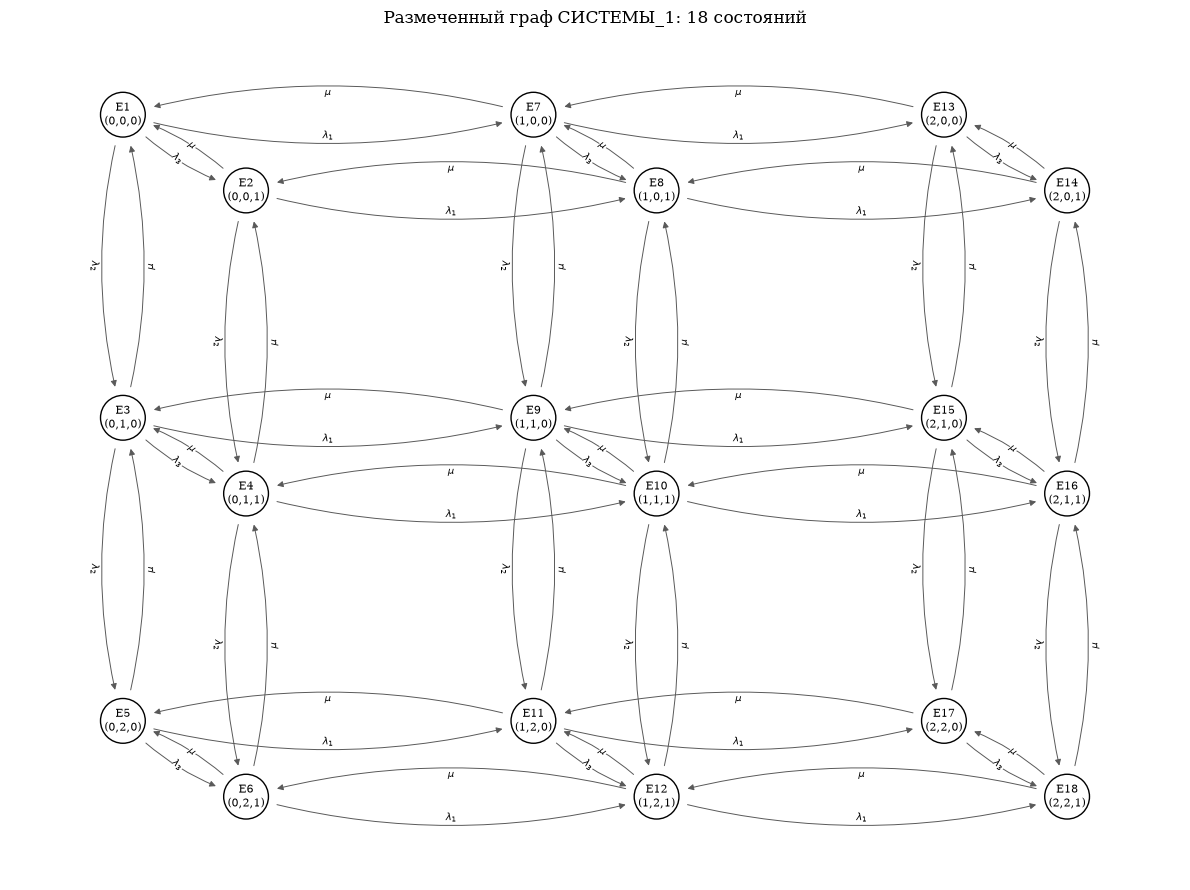

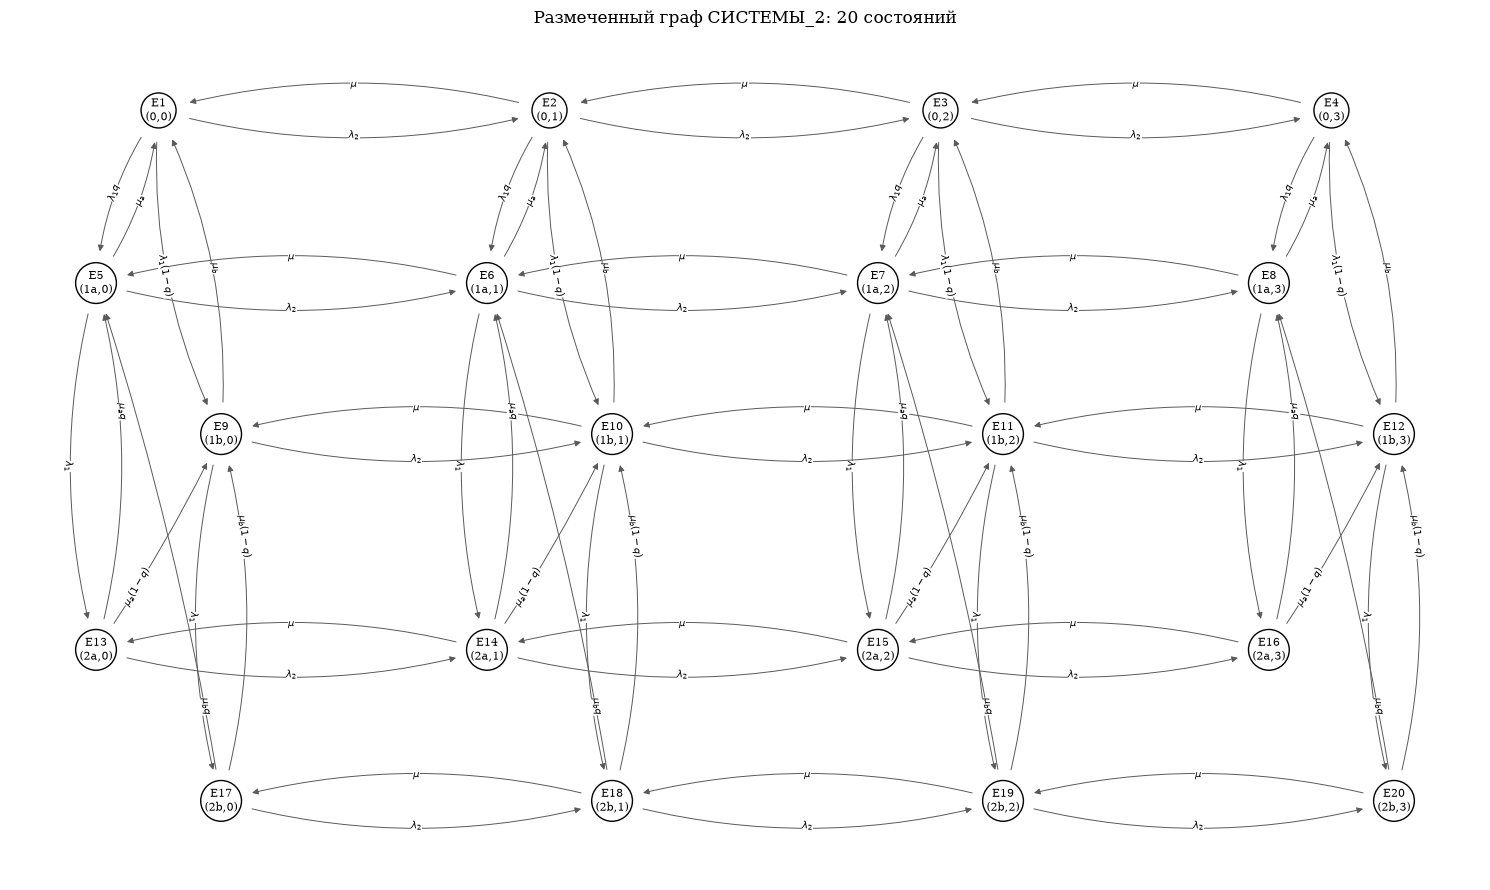

In [7]:
def edge_symbol(source, target, system):
    if system == 1:
        j = next(j for j in range(3) if source[j] != target[j])
        return rf"$\lambda_{j+1}$" if target[j] > source[j] else r"$\mu$"
    if target[1] != source[1]:
        return r"$\lambda_2$" if target[1] > source[1] else r"$\mu$"
    if source[0] == "0":
        return r"$\lambda_1q$" if target[0].endswith("a") else r"$\lambda_1(1-q)$"
    if n_first(target[0]) > n_first(source[0]):
        return r"$\lambda_1$"
    phase = source[0][-1]
    suffix = "" if target[0] == "0" else ("q" if target[0].endswith("a") else "(1-q)")
    return rf"$\mu_{phase}{suffix}$"


def draw_state_graph(states, matrix, system):
    if system == 1:
        pos = {s: np.array([4*s[0]+1.2*s[2], -4*s[1]-s[2]], dtype=float) for s in states}
        size = (12, 9)
    else:
        levels = {"0": (0, 0), "1a": (-0.8, -2.4), "1b": (0.8, -4.5),
                  "2a": (-0.8, -7.5), "2b": (0.8, -9.6)}
        pos = {s: np.array([5*s[1]+levels[s[0]][0], levels[s[0]][1]]) for s in states}
        size = (15, 9)
    fig, ax = plt.subplots(figsize=size)
    for i, source in enumerate(states):
        for j, target in enumerate(states):
            if i == j or matrix[i, j] <= 0:
                continue
            a, b = pos[source], pos[target]
            rad = 0.14 if matrix[j, i] > 0 else 0.04
            ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=9,
                shrinkA=23, shrinkB=23, connectionstyle=f"arc3,rad={rad}",
                linewidth=0.7, color="0.35", zorder=1))
            delta = b-a
            fraction = 0.5
            if system == 2 and n_first(source[0]) == 2 and n_first(target[0]) == 1:
                same_phase = source[0][-1] == target[0][-1]
                fraction = (0.65 if source[0].endswith("a") else 0.72) if same_phase else (
                    0.30 if source[0].endswith("a") else 0.18)
            control = (a+b)/2 + rad*np.array([delta[1], -delta[0]])
            location = (1-fraction)**2*a + 2*(1-fraction)*fraction*control + fraction**2*b
            tangent = 2*(1-fraction)*(control-a) + 2*fraction*(b-control)
            angle = np.degrees(np.arctan2(tangent[1], tangent[0]))
            if angle > 90: angle -= 180
            if angle < -90: angle += 180
            ax.text(*location, edge_symbol(source, target, system), fontsize=7,
                ha="center", va="center", rotation=angle, rotation_mode="anchor",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.3}, zorder=3)
    for i, state in enumerate(states):
        ax.text(*pos[state], f"E{i+1}\n{state_text(state)}", fontsize=8, ha="center", va="center",
            bbox={"boxstyle": "circle,pad=0.35", "facecolor": "white", "edgecolor": "black"}, zorder=4)
    points = np.array(list(pos.values()))
    ax.set(xlim=(points[:, 0].min()-1.1, points[:, 0].max()+1.1),
           ylim=(points[:, 1].min()-1.1, points[:, 1].max()+1.1),
           title=f"Размеченный граф СИСТЕМЫ_{system}: {len(states)} состояний")
    ax.axis("off")
    fig.tight_layout()
    plt.show()


draw_state_graph(states1, G1, 1)
draw_state_graph(states2, G2, 2)

In [8]:
def transition_table(states, matrix, system):
    return pd.DataFrame([{"Откуда": f"E{i+1} {state_text(states[i])}",
                          "Куда": f"E{j+1} {state_text(states[j])}",
                          "Обозначение": edge_symbol(states[i], states[j], system),
                          "Интенсивность, 1/с": matrix[i, j]}
                         for i in range(len(states)) for j in range(len(states))
                         if i != j and matrix[i, j] > 0])


edges1, edges2 = transition_table(states1, G1, 1), transition_table(states2, G2, 2)
for number, table in [(1, edges1), (2, edges2)]:
    display(Markdown(f"<details><summary>Все {len(table)} переходов СИСТЕМЫ_{number}</summary>\n\n" +
                     table.to_markdown(index=False, floatfmt=".9f") + "\n\n</details>"))

<details><summary>Все 66 переходов СИСТЕМЫ_1</summary>

| Откуда      | Куда        | Обозначение   |   Интенсивность, 1/с |
|:------------|:------------|:--------------|---------------------:|
| E1 (0,0,0)  | E2 (0,0,1)  | $\lambda_3$   |          0.200000000 |
| E1 (0,0,0)  | E3 (0,1,0)  | $\lambda_2$   |          0.360000000 |
| E1 (0,0,0)  | E7 (1,0,0)  | $\lambda_1$   |          0.240000000 |
| E2 (0,0,1)  | E1 (0,0,0)  | $\mu$         |          0.200000000 |
| E2 (0,0,1)  | E4 (0,1,1)  | $\lambda_2$   |          0.360000000 |
| E2 (0,0,1)  | E8 (1,0,1)  | $\lambda_1$   |          0.240000000 |
| E3 (0,1,0)  | E1 (0,0,0)  | $\mu$         |          0.200000000 |
| E3 (0,1,0)  | E4 (0,1,1)  | $\lambda_3$   |          0.200000000 |
| E3 (0,1,0)  | E5 (0,2,0)  | $\lambda_2$   |          0.360000000 |
| E3 (0,1,0)  | E9 (1,1,0)  | $\lambda_1$   |          0.240000000 |
| E4 (0,1,1)  | E2 (0,0,1)  | $\mu$         |          0.200000000 |
| E4 (0,1,1)  | E3 (0,1,0)  | $\mu$         |          0.200000000 |
| E4 (0,1,1)  | E6 (0,2,1)  | $\lambda_2$   |          0.360000000 |
| E4 (0,1,1)  | E10 (1,1,1) | $\lambda_1$   |          0.240000000 |
| E5 (0,2,0)  | E3 (0,1,0)  | $\mu$         |          0.200000000 |
| E5 (0,2,0)  | E6 (0,2,1)  | $\lambda_3$   |          0.200000000 |
| E5 (0,2,0)  | E11 (1,2,0) | $\lambda_1$   |          0.240000000 |
| E6 (0,2,1)  | E4 (0,1,1)  | $\mu$         |          0.200000000 |
| E6 (0,2,1)  | E5 (0,2,0)  | $\mu$         |          0.200000000 |
| E6 (0,2,1)  | E12 (1,2,1) | $\lambda_1$   |          0.240000000 |
| E7 (1,0,0)  | E1 (0,0,0)  | $\mu$         |          0.200000000 |
| E7 (1,0,0)  | E8 (1,0,1)  | $\lambda_3$   |          0.200000000 |
| E7 (1,0,0)  | E9 (1,1,0)  | $\lambda_2$   |          0.360000000 |
| E7 (1,0,0)  | E13 (2,0,0) | $\lambda_1$   |          0.240000000 |
| E8 (1,0,1)  | E2 (0,0,1)  | $\mu$         |          0.200000000 |
| E8 (1,0,1)  | E7 (1,0,0)  | $\mu$         |          0.200000000 |
| E8 (1,0,1)  | E10 (1,1,1) | $\lambda_2$   |          0.360000000 |
| E8 (1,0,1)  | E14 (2,0,1) | $\lambda_1$   |          0.240000000 |
| E9 (1,1,0)  | E3 (0,1,0)  | $\mu$         |          0.200000000 |
| E9 (1,1,0)  | E7 (1,0,0)  | $\mu$         |          0.200000000 |
| E9 (1,1,0)  | E10 (1,1,1) | $\lambda_3$   |          0.200000000 |
| E9 (1,1,0)  | E11 (1,2,0) | $\lambda_2$   |          0.360000000 |
| E9 (1,1,0)  | E15 (2,1,0) | $\lambda_1$   |          0.240000000 |
| E10 (1,1,1) | E4 (0,1,1)  | $\mu$         |          0.200000000 |
| E10 (1,1,1) | E8 (1,0,1)  | $\mu$         |          0.200000000 |
| E10 (1,1,1) | E9 (1,1,0)  | $\mu$         |          0.200000000 |
| E10 (1,1,1) | E12 (1,2,1) | $\lambda_2$   |          0.360000000 |
| E10 (1,1,1) | E16 (2,1,1) | $\lambda_1$   |          0.240000000 |
| E11 (1,2,0) | E5 (0,2,0)  | $\mu$         |          0.200000000 |
| E11 (1,2,0) | E9 (1,1,0)  | $\mu$         |          0.200000000 |
| E11 (1,2,0) | E12 (1,2,1) | $\lambda_3$   |          0.200000000 |
| E11 (1,2,0) | E17 (2,2,0) | $\lambda_1$   |          0.240000000 |
| E12 (1,2,1) | E6 (0,2,1)  | $\mu$         |          0.200000000 |
| E12 (1,2,1) | E10 (1,1,1) | $\mu$         |          0.200000000 |
| E12 (1,2,1) | E11 (1,2,0) | $\mu$         |          0.200000000 |
| E12 (1,2,1) | E18 (2,2,1) | $\lambda_1$   |          0.240000000 |
| E13 (2,0,0) | E7 (1,0,0)  | $\mu$         |          0.200000000 |
| E13 (2,0,0) | E14 (2,0,1) | $\lambda_3$   |          0.200000000 |
| E13 (2,0,0) | E15 (2,1,0) | $\lambda_2$   |          0.360000000 |
| E14 (2,0,1) | E8 (1,0,1)  | $\mu$         |          0.200000000 |
| E14 (2,0,1) | E13 (2,0,0) | $\mu$         |          0.200000000 |
| E14 (2,0,1) | E16 (2,1,1) | $\lambda_2$   |          0.360000000 |
| E15 (2,1,0) | E9 (1,1,0)  | $\mu$         |          0.200000000 |
| E15 (2,1,0) | E13 (2,0,0) | $\mu$         |          0.200000000 |
| E15 (2,1,0) | E16 (2,1,1) | $\lambda_3$   |          0.200000000 |
| E15 (2,1,0) | E17 (2,2,0) | $\lambda_2$   |          0.360000000 |
| E16 (2,1,1) | E10 (1,1,1) | $\mu$         |          0.200000000 |
| E16 (2,1,1) | E14 (2,0,1) | $\mu$         |          0.200000000 |
| E16 (2,1,1) | E15 (2,1,0) | $\mu$         |          0.200000000 |
| E16 (2,1,1) | E18 (2,2,1) | $\lambda_2$   |          0.360000000 |
| E17 (2,2,0) | E11 (1,2,0) | $\mu$         |          0.200000000 |
| E17 (2,2,0) | E15 (2,1,0) | $\mu$         |          0.200000000 |
| E17 (2,2,0) | E18 (2,2,1) | $\lambda_3$   |          0.200000000 |
| E18 (2,2,1) | E12 (1,2,1) | $\mu$         |          0.200000000 |
| E18 (2,2,1) | E16 (2,1,1) | $\mu$         |          0.200000000 |
| E18 (2,2,1) | E17 (2,2,0) | $\mu$         |          0.200000000 |

</details>

<details><summary>Все 70 переходов СИСТЕМЫ_2</summary>

| Откуда     | Куда       | Обозначение      |   Интенсивность, 1/с |
|:-----------|:-----------|:-----------------|---------------------:|
| E1 (0,0)   | E2 (0,1)   | $\lambda_2$      |          0.560000000 |
| E1 (0,0)   | E5 (1a,0)  | $\lambda_1q$     |          0.017884447 |
| E1 (0,0)   | E9 (1b,0)  | $\lambda_1(1-q)$ |          0.222115553 |
| E2 (0,1)   | E1 (0,0)   | $\mu$            |          0.200000000 |
| E2 (0,1)   | E3 (0,2)   | $\lambda_2$      |          0.560000000 |
| E2 (0,1)   | E6 (1a,1)  | $\lambda_1q$     |          0.017884447 |
| E2 (0,1)   | E10 (1b,1) | $\lambda_1(1-q)$ |          0.222115553 |
| E3 (0,2)   | E2 (0,1)   | $\mu$            |          0.200000000 |
| E3 (0,2)   | E4 (0,3)   | $\lambda_2$      |          0.560000000 |
| E3 (0,2)   | E7 (1a,2)  | $\lambda_1q$     |          0.017884447 |
| E3 (0,2)   | E11 (1b,2) | $\lambda_1(1-q)$ |          0.222115553 |
| E4 (0,3)   | E3 (0,2)   | $\mu$            |          0.200000000 |
| E4 (0,3)   | E8 (1a,3)  | $\lambda_1q$     |          0.017884447 |
| E4 (0,3)   | E12 (1b,3) | $\lambda_1(1-q)$ |          0.222115553 |
| E5 (1a,0)  | E1 (0,0)   | $\mu_a$          |          0.029807411 |
| E5 (1a,0)  | E6 (1a,1)  | $\lambda_2$      |          0.560000000 |
| E5 (1a,0)  | E13 (2a,0) | $\lambda_1$      |          0.240000000 |
| E6 (1a,1)  | E2 (0,1)   | $\mu_a$          |          0.029807411 |
| E6 (1a,1)  | E5 (1a,0)  | $\mu$            |          0.200000000 |
| E6 (1a,1)  | E7 (1a,2)  | $\lambda_2$      |          0.560000000 |
| E6 (1a,1)  | E14 (2a,1) | $\lambda_1$      |          0.240000000 |
| E7 (1a,2)  | E3 (0,2)   | $\mu_a$          |          0.029807411 |
| E7 (1a,2)  | E6 (1a,1)  | $\mu$            |          0.200000000 |
| E7 (1a,2)  | E8 (1a,3)  | $\lambda_2$      |          0.560000000 |
| E7 (1a,2)  | E15 (2a,2) | $\lambda_1$      |          0.240000000 |
| E8 (1a,3)  | E4 (0,3)   | $\mu_a$          |          0.029807411 |
| E8 (1a,3)  | E7 (1a,2)  | $\mu$            |          0.200000000 |
| E8 (1a,3)  | E16 (2a,3) | $\lambda_1$      |          0.240000000 |
| E9 (1b,0)  | E1 (0,0)   | $\mu_b$          |          0.370192589 |
| E9 (1b,0)  | E10 (1b,1) | $\lambda_2$      |          0.560000000 |
| E9 (1b,0)  | E17 (2b,0) | $\lambda_1$      |          0.240000000 |
| E10 (1b,1) | E2 (0,1)   | $\mu_b$          |          0.370192589 |
| E10 (1b,1) | E9 (1b,0)  | $\mu$            |          0.200000000 |
| E10 (1b,1) | E11 (1b,2) | $\lambda_2$      |          0.560000000 |
| E10 (1b,1) | E18 (2b,1) | $\lambda_1$      |          0.240000000 |
| E11 (1b,2) | E3 (0,2)   | $\mu_b$          |          0.370192589 |
| E11 (1b,2) | E10 (1b,1) | $\mu$            |          0.200000000 |
| E11 (1b,2) | E12 (1b,3) | $\lambda_2$      |          0.560000000 |
| E11 (1b,2) | E19 (2b,2) | $\lambda_1$      |          0.240000000 |
| E12 (1b,3) | E4 (0,3)   | $\mu_b$          |          0.370192589 |
| E12 (1b,3) | E11 (1b,2) | $\mu$            |          0.200000000 |
| E12 (1b,3) | E20 (2b,3) | $\lambda_1$      |          0.240000000 |
| E13 (2a,0) | E5 (1a,0)  | $\mu_aq$         |          0.002221204 |
| E13 (2a,0) | E9 (1b,0)  | $\mu_a(1-q)$     |          0.027586207 |
| E13 (2a,0) | E14 (2a,1) | $\lambda_2$      |          0.560000000 |
| E14 (2a,1) | E6 (1a,1)  | $\mu_aq$         |          0.002221204 |
| E14 (2a,1) | E10 (1b,1) | $\mu_a(1-q)$     |          0.027586207 |
| E14 (2a,1) | E13 (2a,0) | $\mu$            |          0.200000000 |
| E14 (2a,1) | E15 (2a,2) | $\lambda_2$      |          0.560000000 |
| E15 (2a,2) | E7 (1a,2)  | $\mu_aq$         |          0.002221204 |
| E15 (2a,2) | E11 (1b,2) | $\mu_a(1-q)$     |          0.027586207 |
| E15 (2a,2) | E14 (2a,1) | $\mu$            |          0.200000000 |
| E15 (2a,2) | E16 (2a,3) | $\lambda_2$      |          0.560000000 |
| E16 (2a,3) | E8 (1a,3)  | $\mu_aq$         |          0.002221204 |
| E16 (2a,3) | E12 (1b,3) | $\mu_a(1-q)$     |          0.027586207 |
| E16 (2a,3) | E15 (2a,2) | $\mu$            |          0.200000000 |
| E17 (2b,0) | E5 (1a,0)  | $\mu_bq$         |          0.027586207 |
| E17 (2b,0) | E9 (1b,0)  | $\mu_b(1-q)$     |          0.342606382 |
| E17 (2b,0) | E18 (2b,1) | $\lambda_2$      |          0.560000000 |
| E18 (2b,1) | E6 (1a,1)  | $\mu_bq$         |          0.027586207 |
| E18 (2b,1) | E10 (1b,1) | $\mu_b(1-q)$     |          0.342606382 |
| E18 (2b,1) | E17 (2b,0) | $\mu$            |          0.200000000 |
| E18 (2b,1) | E19 (2b,2) | $\lambda_2$      |          0.560000000 |
| E19 (2b,2) | E7 (1a,2)  | $\mu_bq$         |          0.027586207 |
| E19 (2b,2) | E11 (1b,2) | $\mu_b(1-q)$     |          0.342606382 |
| E19 (2b,2) | E18 (2b,1) | $\mu$            |          0.200000000 |
| E19 (2b,2) | E20 (2b,3) | $\lambda_2$      |          0.560000000 |
| E20 (2b,3) | E8 (1a,3)  | $\mu_bq$         |          0.027586207 |
| E20 (2b,3) | E12 (1b,3) | $\mu_b(1-q)$     |          0.342606382 |
| E20 (2b,3) | E19 (2b,2) | $\mu$            |          0.200000000 |

</details>

### Полные матрицы

В таблицах ниже вывод округлён до четырёх знаков для чтения. В переменных `G1`,
`G2` и в расчёте используется полная точность. В Excel те же матрицы названы Q1/Q2.
Отрицательная диагональ содержит интенсивность выхода со знаком минус, а не
отрицательную вероятность.

**Матрица G1, 1/с.**

|     |      E1 |      E2 |      E3 |      E4 |      E5 |      E6 |      E7 |      E8 |      E9 |     E10 |     E11 |     E12 |     E13 |     E14 |     E15 |     E16 |     E17 |     E18 |
|:----|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|
| E1  | -0.8000 |  0.2000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E2  |  0.2000 | -0.8000 |  0.0000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E3  |  0.2000 |  0.0000 | -1.0000 |  0.2000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E4  |  0.0000 |  0.2000 |  0.2000 | -1.0000 |  0.0000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E5  |  0.0000 |  0.0000 |  0.2000 |  0.0000 | -0.6400 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E6  |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.2000 | -0.6400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E7  |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 | -1.0000 |  0.2000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E8  |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 | -1.0000 |  0.0000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E9  |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 | -1.2000 |  0.2000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |
| E10 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.2000 | -1.2000 |  0.0000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |
| E11 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 | -0.8400 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |
| E12 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.2000 | -0.8400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |
| E13 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 | -0.7600 |  0.2000 |  0.3600 |  0.0000 |  0.0000 |  0.0000 |
| E14 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 | -0.7600 |  0.0000 |  0.3600 |  0.0000 |  0.0000 |
| E15 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 | -0.9600 |  0.2000 |  0.3600 |  0.0000 |
| E16 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.2000 | -0.9600 |  0.0000 |  0.3600 |
| E17 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 | -0.6000 |  0.2000 |
| E18 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 |  0.2000 | -0.6000 |

**Матрица G2, 1/с.**

|     |      E1 |      E2 |      E3 |      E4 |      E5 |      E6 |      E7 |      E8 |      E9 |     E10 |     E11 |     E12 |     E13 |     E14 |     E15 |     E16 |     E17 |     E18 |     E19 |     E20 |
|:----|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|--------:|
| E1  | -0.8000 |  0.5600 |  0.0000 |  0.0000 |  0.0179 |  0.0000 |  0.0000 |  0.0000 |  0.2221 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E2  |  0.2000 | -1.0000 |  0.5600 |  0.0000 |  0.0000 |  0.0179 |  0.0000 |  0.0000 |  0.0000 |  0.2221 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E3  |  0.0000 |  0.2000 | -1.0000 |  0.5600 |  0.0000 |  0.0000 |  0.0179 |  0.0000 |  0.0000 |  0.0000 |  0.2221 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E4  |  0.0000 |  0.0000 |  0.2000 | -0.4400 |  0.0000 |  0.0000 |  0.0000 |  0.0179 |  0.0000 |  0.0000 |  0.0000 |  0.2221 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E5  |  0.0298 |  0.0000 |  0.0000 |  0.0000 | -0.8298 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E6  |  0.0000 |  0.0298 |  0.0000 |  0.0000 |  0.2000 | -1.0298 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E7  |  0.0000 |  0.0000 |  0.0298 |  0.0000 |  0.0000 |  0.2000 | -1.0298 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E8  |  0.0000 |  0.0000 |  0.0000 |  0.0298 |  0.0000 |  0.0000 |  0.2000 | -0.4698 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E9  |  0.3702 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 | -1.1702 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |  0.0000 |
| E10 |  0.0000 |  0.3702 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 | -1.3702 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |  0.0000 |
| E11 |  0.0000 |  0.0000 |  0.3702 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 | -1.3702 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |  0.0000 |
| E12 |  0.0000 |  0.0000 |  0.0000 |  0.3702 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 | -0.8102 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2400 |
| E13 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0022 |  0.0000 |  0.0000 |  0.0000 |  0.0276 |  0.0000 |  0.0000 |  0.0000 | -0.5898 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E14 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0022 |  0.0000 |  0.0000 |  0.0000 |  0.0276 |  0.0000 |  0.0000 |  0.2000 | -0.7898 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E15 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0022 |  0.0000 |  0.0000 |  0.0000 |  0.0276 |  0.0000 |  0.0000 |  0.2000 | -0.7898 |  0.5600 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E16 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0022 |  0.0000 |  0.0000 |  0.0000 |  0.0276 |  0.0000 |  0.0000 |  0.2000 | -0.2298 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |
| E17 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0276 |  0.0000 |  0.0000 |  0.0000 |  0.3426 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 | -0.9302 |  0.5600 |  0.0000 |  0.0000 |
| E18 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0276 |  0.0000 |  0.0000 |  0.0000 |  0.3426 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 | -1.1302 |  0.5600 |  0.0000 |
| E19 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0276 |  0.0000 |  0.0000 |  0.0000 |  0.3426 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 | -1.1302 |  0.5600 |
| E20 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0276 |  0.0000 |  0.0000 |  0.0000 |  0.3426 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.2000 | -0.5702 |

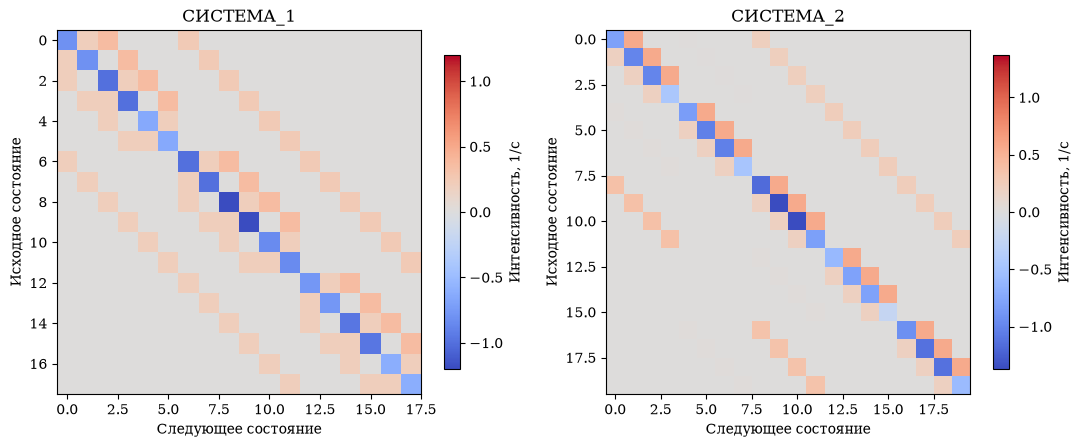

In [9]:
for number, matrix in [(1, G1), (2, G2)]:
    labels = [f"E{i+1}" for i in range(len(matrix))]
    display(Markdown(f"**Матрица G{number}, 1/с.**"))
    show_table(pd.DataFrame(matrix, index=labels, columns=labels), digits=4)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, matrix, title in zip(axes, [G1, G2], ["СИСТЕМА_1", "СИСТЕМА_2"]):
    vmax = np.abs(matrix).max()
    picture = ax.imshow(matrix, cmap="coolwarm", vmin=-vmax, vmax=vmax)
    ax.set(title=title, xlabel="Следующее состояние", ylabel="Исходное состояние")
    fig.colorbar(picture, ax=ax, label="Интенсивность, 1/с", shrink=0.8)
fig.tight_layout()
plt.show()

## 5. Стационарные вероятности — форма 1

В установившемся режиме входящий и выходящий вероятностные потоки каждого состояния
сбалансированы:

$$\boldsymbol pG=0,\qquad\sum_i p_i=1,\qquad p_i\geq0.$$

Для численного решения одно зависимое уравнение в $G^{\mathsf T}\boldsymbol p^{\mathsf T}=0$
заменяется нормировкой. Вероятности не назначаются вручную и не берутся из Excel.

In [10]:
def stationary(matrix):
    equations = matrix.T.copy()
    right = np.zeros(len(matrix))
    equations[-1] = 1
    right[-1] = 1
    probabilities = np.linalg.solve(equations, right)
    if probabilities.min() < -1e-12:
        raise ValueError("Получена отрицательная вероятность: проверь переходы.")
    np.testing.assert_allclose(probabilities.sum(), 1, atol=1e-12)
    np.testing.assert_allclose(probabilities @ matrix, 0, atol=1e-12)
    return probabilities


p1, p2 = stationary(G1), stationary(G2)
form1_rows = []
for i in range(max(len(states1), len(states2))):
    form1_rows.append({"№": i+1,
        "СИСТЕМА_1: состояние": state_text(states1[i]) if i < len(states1) else "—",
        "СИСТЕМА_1: p": f"{p1[i]:.9f}" if i < len(p1) else "—",
        "СИСТЕМА_2: состояние": state_text(states2[i]), "СИСТЕМА_2: p": f"{p2[i]:.9f}"})
form1 = pd.DataFrame(form1_rows)
show_table(form1, index=False, digits=9)

|   № | СИСТЕМА_1: состояние   | СИСТЕМА_1: p   | СИСТЕМА_2: состояние   |   СИСТЕМА_2: p |
|----:|:-----------------------|:---------------|:-----------------------|---------------:|
|   1 | (0,0,0)                | 0.022742159    | (0,0)                  |    0.009583262 |
|   2 | (0,0,1)                | 0.022742159    | (0,1)                  |    0.026833132 |
|   3 | (0,1,0)                | 0.040935885    | (0,2)                  |    0.075132770 |
|   4 | (0,1,1)                | 0.040935885    | (0,3)                  |    0.210371757 |
|   5 | (0,2,0)                | 0.073684594    | (1a,0)                 |    0.001115026 |
|   6 | (0,2,1)                | 0.073684594    | (1a,1)                 |    0.003122072 |
|   7 | (1,0,0)                | 0.027290590    | (1a,2)                 |    0.008741801 |
|   8 | (1,0,1)                | 0.027290590    | (1a,3)                 |    0.024477044 |
|   9 | (1,1,0)                | 0.049123062    | (1b,0)                 |    0.006123155 |
|  10 | (1,1,1)                | 0.049123062    | (1b,1)                 |    0.017144835 |
|  11 | (1,2,0)                | 0.088421512    | (1b,2)                 |    0.048005538 |
|  12 | (1,2,1)                | 0.088421512    | (1b,3)                 |    0.134415507 |
|  13 | (2,0,0)                | 0.032748708    | (2a,0)                 |    0.008977840 |
|  14 | (2,0,1)                | 0.032748708    | (2a,1)                 |    0.025137952 |
|  15 | (2,1,0)                | 0.058947675    | (2a,2)                 |    0.070386264 |
|  16 | (2,1,1)                | 0.058947675    | (2a,3)                 |    0.197081541 |
|  17 | (2,2,0)                | 0.106105815    | (2b,0)                 |    0.003969710 |
|  18 | (2,2,1)                | 0.106105815    | (2b,1)                 |    0.011115189 |
|  19 | —                      | —              | (2b,2)                 |    0.031122528 |
|  20 | —                      | —              | (2b,3)                 |    0.087143078 |

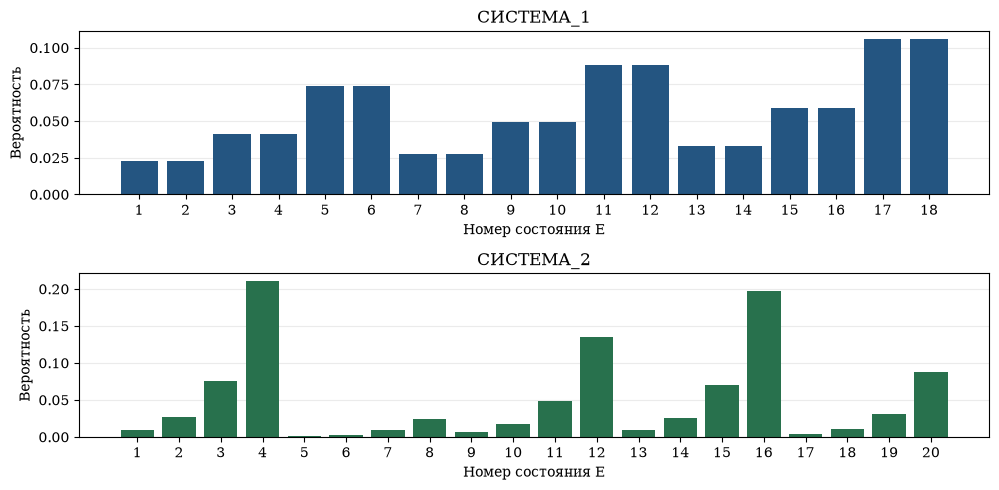

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5))
for ax, probabilities, color, title in zip(axes, [p1, p2], [BLUE, GREEN], ["СИСТЕМА_1", "СИСТЕМА_2"]):
    ax.bar(np.arange(1, len(probabilities)+1), probabilities, color=color)
    ax.set(title=title, xlabel="Номер состояния E", ylabel="Вероятность",
           xticks=np.arange(1, len(probabilities)+1))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 6. Характеристики через вероятности состояний

$K_j$ — вместимость ветви, $A_j=\{s:n_j(s)<K_j\}$ — принимающие состояния.
Нагрузка и загрузка имеют разный смысл:

$$y_j=\lambda_jb,\qquad\rho_j=\sum_{s:n_j(s)>0}p_s.$$

Нагрузка может быть больше единицы; загрузка одного прибора — вероятность занятости.
Суммарная загрузка $R=\sum_j\rho_j$ — среднее число занятых приборов.

$$l_j=\sum_s\max(n_j(s)-1,0)p_s,\qquad m_j=\sum_s n_j(s)p_s,$$
$$\pi_j=\sum_{s:n_j(s)=K_j}p_s,\qquad\lambda_j'=\lambda_j(1-\pi_j).$$

Поскольку входные потоки пуассоновские (свойство PASTA), поступающая заявка видит
стационарные вероятности состояний. Общее число потерянных заявок взвешивается по
входным потокам:

$$\pi=\frac{\sum_j\lambda_j\pi_j}{\lambda},\qquad\Lambda'=\sum_j\lambda_j'.$$

### Среднее ожидание: прямой расчёт, без формулы Литтла

В принимающем состоянии $s$ условное ожидание новой заявки:

$$d_j(s)=\begin{cases}
0,&n_j(s)=0,\\
n_j(s)b,&\text{экспоненциальный прибор},\\
\dfrac1{\mu_{\varphi(s)}}+(n_j(s)-1)b,&H_\nu\text{-прибор и }n_j(s)>0.
\end{cases}$$

У H-прибора остаток текущего обслуживания равен в среднем $1/\mu_\varphi$;
после него каждая ожидающая перед новой заявкой имеет среднее обслуживание $b$.

$$w_j=\frac{\sum_{s\in A_j}p_s d_j(s)}{1-\pi_j},\qquad u_j=w_j+b.$$

Делитель $1-\pi_j$ переводит среднее к **принятым** заявкам. Для П1 второй системы
принимаются только $0,1_a,1_b$.

Общие времена взвешиваются по обслуженному потоку:

$$W=\frac{\sum_j\lambda_j'w_j}{\Lambda'},\qquad U=\frac{\sum_j\lambda_j'u_j}{\Lambda'}.$$

Для числа заявок, очереди, нагрузки и загрузки суммарное значение — обычная сумма
по ветвям. Времена и вероятность потери так складывать нельзя.

In [12]:
def characteristics(states, probabilities, lam, system):
    counts = occupancy(states, system)
    capacities = CAPACITY1 if system == 1 else CAPACITY2
    arrivals = lam * (ALPHA1 if system == 1 else ALPHA2)
    metrics = {key: [] for key in ["load", "utilization", "queue_length", "number_in_system",
                                   "wait_time", "sojourn_time", "loss_probability", "throughput"]}
    for j, capacity in enumerate(capacities):
        n = counts[:, j]
        busy = probabilities[n > 0].sum()
        queue = np.dot(np.maximum(n-1, 0), probabilities)
        number = np.dot(n, probabilities)
        loss = probabilities[n == capacity].sum()
        accepting = n < capacity
        delay = n * B
        if system == 2 and j == 0:
            rates = np.array([MU_A if label.endswith("a") else MU_B for label, _ in states])
            delay = np.where(n > 0, 1/rates + (n-1)*B, 0)
        wait = np.dot(probabilities[accepting], delay[accepting]) / (1-loss)
        values = [arrivals[j]*B, busy, queue, number, wait, wait+B, loss, arrivals[j]*(1-loss)]
        for key, value in zip(metrics, values):
            metrics[key].append(float(value))
    metrics = {key: np.array(value) for key, value in metrics.items()}
    total = {key: float(metrics[key].sum()) for key in ["load", "utilization", "queue_length", "number_in_system", "throughput"]}
    total["loss_probability"] = float(np.dot(arrivals, metrics["loss_probability"]) / lam)
    for key in ["wait_time", "sojourn_time"]:
        total[key] = float(np.dot(metrics["throughput"], metrics[key]) / total["throughput"])
    return metrics, total


metrics1, total1 = characteristics(states1, p1, BASE_LAMBDA, 1)
metrics2, total2 = characteristics(states2, p2, BASE_LAMBDA, 2)

### Форма 2

Формулы приведены выше; таблица содержит характеристики каждого прибора и системы.
«—» означает, что П3 во второй системе отсутствует. В строке «Сумм.» времени стоит
взвешенное среднее системы, а не сумма времён отдельных ветвей.

In [13]:
METRICS = {
    "load": "Нагрузка", "utilization": "Загрузка", "queue_length": "Длина очереди",
    "number_in_system": "Число заявок", "wait_time": "Время ожидания, с",
    "sojourn_time": "Время пребывания, с", "loss_probability": "Вероятность потери",
    "throughput": "Производительность, заявок/с",
}
form2_rows = []
for key, label in METRICS.items():
    for j in range(3):
        form2_rows.append({"Характеристика": label, "Прибор": f"П{j+1}",
                          "СИСТЕМА_1": f"{metrics1[key][j]:.6f}",
                          "СИСТЕМА_2": f"{metrics2[key][j]:.6f}" if j < 2 else "—"})
    form2_rows.append({"Характеристика": label, "Прибор": "Сумм.",
                      "СИСТЕМА_1": f"{total1[key]:.6f}", "СИСТЕМА_2": f"{total2[key]:.6f}"})
form2 = pd.DataFrame(form2_rows)
show_table(form2, index=False)

| Характеристика               | Прибор   |   СИСТЕМА_1 | СИСТЕМА_2   |
|:-----------------------------|:---------|------------:|:------------|
| Нагрузка                     | П1       |    1.200000 | 1.200000    |
| Нагрузка                     | П2       |    1.800000 | 2.800000    |
| Нагрузка                     | П3       |    1.000000 | —           |
| Нагрузка                     | Сумм.    |    4.000000 | 4.000000    |
| Загрузка                     | П1       |    0.725275 | 0.678079    |
| Загрузка                     | П2       |    0.834437 | 0.970231    |
| Загрузка                     | П3       |    0.500000 | —           |
| Загрузка                     | Сумм.    |    2.059712 | 1.648310    |
| Длина очереди                | П1       |    0.395604 | 0.434934    |
| Длина очереди                | П2       |    0.536424 | 1.540367    |
| Длина очереди                | П3       |    0.000000 | —           |
| Длина очереди                | Сумм.    |    0.932028 | 1.975301    |
| Число заявок                 | П1       |    1.120879 | 1.113013    |
| Число заявок                 | П2       |    1.370861 | 2.510598    |
| Число заявок                 | П3       |    0.500000 | —           |
| Число заявок                 | Сумм.    |    2.991740 | 3.623611    |
| Время ожидания, с            | П1       |    2.727273 | 3.207105    |
| Время ожидания, с            | П2       |    3.214286 | 7.938144    |
| Время ожидания, с            | П3       |    0.000000 | —           |
| Время ожидания, с            | Сумм.    |    2.262521 | 5.991897    |
| Время пребывания, с          | П1       |    7.727273 | 8.207105    |
| Время пребывания, с          | П2       |    8.214286 | 12.938144   |
| Время пребывания, с          | П3       |    5.000000 | —           |
| Время пребывания, с          | Сумм.    |    7.262521 | 10.991897   |
| Вероятность потери           | П1       |    0.395604 | 0.434934    |
| Вероятность потери           | П2       |    0.536424 | 0.653489    |
| Вероятность потери           | П3       |    0.500000 | —           |
| Вероятность потери           | Сумм.    |    0.485072 | 0.587922    |
| Производительность, заявок/с | П1       |    0.145055 | 0.135616    |
| Производительность, заявок/с | П2       |    0.166887 | 0.194046    |
| Производительность, заявок/с | П3       |    0.100000 | —           |
| Производительность, заявок/с | Сумм.    |    0.411942 | 0.329662    |

## 7. Проверка результата

По методичке фундаментальные зависимости применяются **после** прямого расчёта:

$$l_j=\lambda_j'w_j,\qquad m_j=\lambda_j'u_j,\qquad
L=\Lambda'W,\quad M=\Lambda'U.$$

Дополнительно проверяем сумму вероятностей, баланс, нулевые суммы строк $G$, ранг
$|\mathcal S|-1$ и производительность по завершениям обслуживания. Последняя считается
независимо от потерь: для экспоненциального прибора это $\mu\rho_j$; для H-прибора —
сумма $p_s\mu_{\varphi(s)}$ по занятым состояниям.

In [14]:
check_rows = []
for system, states, matrix, probabilities, metrics, total in [
    (1, states1, G1, p1, metrics1, total1), (2, states2, G2, p2, metrics2, total2)]:
    counts = occupancy(states, system)
    completion = MU * metrics["utilization"].copy()
    if system == 2:
        rates = np.array([MU_A if label.endswith("a") else MU_B for label, _ in states])
        completion[0] = np.dot(probabilities[counts[:, 0] > 0], rates[counts[:, 0] > 0])
    np.testing.assert_allclose(matrix.sum(axis=1), 0, atol=1e-12)
    assert np.linalg.matrix_rank(matrix) == len(states)-1
    np.testing.assert_allclose(completion, metrics["throughput"], atol=1e-12)
    np.testing.assert_allclose(metrics["queue_length"], metrics["throughput"]*metrics["wait_time"], atol=1e-12)
    np.testing.assert_allclose(metrics["number_in_system"], metrics["throughput"]*metrics["sojourn_time"], atol=1e-12)
    np.testing.assert_allclose([total["queue_length"], total["number_in_system"]],
        [total["throughput"]*total["wait_time"], total["throughput"]*total["sojourn_time"]], atol=1e-12)
    np.testing.assert_allclose(total["throughput"]+BASE_LAMBDA*total["loss_probability"], BASE_LAMBDA, atol=1e-12)
    check_rows.append({"Система": f"СИСТЕМА_{system}", "Сумма p": probabilities.sum(),
        "min p": probabilities.min(), "max |pG|": np.max(abs(probabilities @ matrix)),
        "Поток по поступлениям": total["throughput"], "Поток по обслуживаниям": completion.sum(),
        "L−Λ′W": total["queue_length"]-total["throughput"]*total["wait_time"]})
show_table(pd.DataFrame(check_rows), index=False, digits=10)
print("Нормировка, баланс потоков и проверки Литтла выполнены для обеих систем.")

| Система   |      Сумма p |        min p |     max |pG| |   Поток по поступлениям |   Поток по обслуживаниям |         L−Λ′W |
|:----------|-------------:|-------------:|-------------:|------------------------:|-------------------------:|--------------:|
| СИСТЕМА_1 | 1.0000000000 | 0.0227421585 | 0.0000000000 |            0.4119423623 |             0.4119423623 | -0.0000000000 |
| СИСТЕМА_2 | 1.0000000000 | 0.0011150257 | 0.0000000000 |            0.3296620173 |             0.3296620173 |  0.0000000000 |

Нормировка, баланс потоков и проверки Литтла выполнены для обеих систем.


### Дополнительная проверка через независимые ветви

Пуассоновский поток после независимой маршрутизации распадается на независимые
пуассоновские потоки. В СИСТЕМЕ_1 локальные вероятности $M/M/1/K$:

$$P_j(n)=\frac{(\lambda_j/\mu)^n}{\sum_{r=0}^{K_j}(\lambda_j/\mu)^r},\qquad
p(n_1,n_2,n_3)=\prod_jP_j(n_j).$$

Эта формула корректна и при $\lambda_j=\mu$. Для СИСТЕМЫ_2 независимо строим локальную
матрицу П1 на пяти состояниях и локальную матрицу П2 на четырёх. Их сумма Кронекера
должна совпасть с полным генератором:

$$G_2=H\otimes I_4+I_5\otimes M_2.$$

In [15]:
def mm1k_prob(arrival, capacity):
    weights = (arrival/MU)**np.arange(capacity+1)
    return weights / weights.sum()


local1 = [mm1k_prob(BASE_LAMBDA*a, k) for a, k in zip(ALPHA1, CAPACITY1)]
p1_product = np.array([np.prod([local1[j][s[j]] for j in range(3)]) for s in states1])
np.testing.assert_allclose(p1, p1_product, rtol=1e-11, atol=1e-12)

arrival1, arrival2 = BASE_LAMBDA*ALPHA2
q = Q_SLOW
H = np.array([
    [-arrival1, arrival1*q, arrival1*(1-q), 0, 0],
    [MU_A, -MU_A-arrival1, 0, arrival1, 0],
    [MU_B, 0, -MU_B-arrival1, 0, arrival1],
    [0, MU_A*q, MU_A*(1-q), -MU_A, 0],
    [0, MU_B*q, MU_B*(1-q), 0, -MU_B],
])
M2 = np.zeros((4, 4))
for i in range(4):
    if i < 3: M2[i, i+1] = arrival2
    if i > 0: M2[i, i-1] = MU
    M2[i, i] = -M2[i].sum()
np.testing.assert_allclose(G2, np.kron(H, np.eye(4))+np.kron(np.eye(5), M2), atol=1e-12)
p2_product = np.kron(stationary(H), mm1k_prob(arrival2, 3))
np.testing.assert_allclose(p2, p2_product, rtol=1e-11, atol=1e-12)
print("Независимая проверка по локальным ветвям совпала с решением полных моделей.")

Независимая проверка по локальным ветвям совпала с решением полных моделей.


## 8. Сравнение при заданной нагрузке

Сравниваем характеристики при $\lambda=0.8$ заявки/с. Критерий — максимум
$\Lambda'$, а не минимум времени или максимум загрузки.

In [16]:
summary = pd.DataFrame({"СИСТЕМА_1": pd.Series(total1), "СИСТЕМА_2": pd.Series(total2)}).reindex(METRICS)
summary.index = [METRICS[key] for key in summary.index]
show_table(summary)
winner = 1 if total1["throughput"] > total2["throughput"] else 2
improvement = (total1["throughput"]/total2["throughput"] - 1)*100
display(Markdown(f"По критерию максимальной производительности выбрана **СИСТЕМА_{winner}**. "
    f"При λ={BASE_LAMBDA:g}: **{total1['throughput']:.6f}** против **{total2['throughput']:.6f}** заявки/с. "
    f"Относительное преимущество первой над второй: **{improvement:.3f}%**."))

|                              |   СИСТЕМА_1 |   СИСТЕМА_2 |
|:-----------------------------|------------:|------------:|
| Нагрузка                     |    4.000000 |    4.000000 |
| Загрузка                     |    2.059712 |    1.648310 |
| Длина очереди                |    0.932028 |    1.975301 |
| Число заявок                 |    2.991740 |    3.623611 |
| Время ожидания, с            |    2.262521 |    5.991897 |
| Время пребывания, с          |    7.262521 |   10.991897 |
| Вероятность потери           |    0.485072 |    0.587922 |
| Производительность, заявок/с |    0.411942 |    0.329662 |

По критерию максимальной производительности выбрана **СИСТЕМА_1**. При λ=0.8: **0.411942** против **0.329662** заявки/с. Относительное преимущество первой над второй: **24.959%**.

## 9. Варьирование интенсивности поступлений

Для каждого $\lambda=0.1,0.2,\ldots,2.0$ заново строим обе матрицы, решаем баланс
и считаем характеристики. Среднее обслуживания, коэффициент вариации и очереди
фиксированы. Стационарные вероятности при базовой нагрузке на другие точки не переносятся.

In [17]:
sweep_rows = []
for lam in np.round(np.arange(0.1, 2.01, 0.1), 1):
    a = characteristics(states1, stationary(build_system1(lam)), lam, 1)[1]
    b = characteristics(states2, stationary(build_system2(lam)), lam, 2)[1]
    sweep_rows.append({"λ": lam, "Λ′1": a["throughput"], "Λ′2": b["throughput"],
        "π1": a["loss_probability"], "π2": b["loss_probability"],
        "U1, с": a["sojourn_time"], "U2, с": b["sojourn_time"],
        "L1": a["queue_length"], "L2": b["queue_length"]})
sweep = pd.DataFrame(sweep_rows)
show_table(sweep, index=False)

|        λ |      Λ′1 |      Λ′2 |       π1 |       π2 |    U1, с |     U2, с |       L1 |       L2 |
|---------:|---------:|---------:|---------:|---------:|---------:|----------:|---------:|---------:|
| 0.100000 | 0.094861 | 0.096776 | 0.051394 | 0.032241 | 5.620660 |  6.848345 | 0.058876 | 0.178875 |
| 0.200000 | 0.175086 | 0.174559 | 0.124568 | 0.127203 | 6.069700 |  8.278646 | 0.187290 | 0.572319 |
| 0.300000 | 0.239648 | 0.227792 | 0.201175 | 0.240692 | 6.403675 |  9.251999 | 0.336387 | 0.968573 |
| 0.400000 | 0.290825 | 0.263188 | 0.272937 | 0.342029 | 6.659301 |  9.890955 | 0.482566 | 1.287243 |
| 0.500000 | 0.331450 | 0.287660 | 0.337099 | 0.424680 | 6.860052 | 10.318160 | 0.616515 | 1.529821 |
| 0.600000 | 0.363981 | 0.305469 | 0.393366 | 0.490884 | 7.021210 | 10.614861 | 0.735681 | 1.715168 |
| 0.700000 | 0.390332 | 0.319012 | 0.442383 | 0.544268 | 7.153012 | 10.829809 | 0.840389 | 1.859780 |
| 0.800000 | 0.411942 | 0.329662 | 0.485072 | 0.587922 | 7.262521 | 10.991897 | 0.932028 | 1.975301 |
| 0.900000 | 0.429882 | 0.338251 | 0.522354 | 0.624166 | 7.354751 | 11.118556 | 1.012264 | 2.069607 |
| 1.000000 | 0.444946 | 0.345312 | 0.555054 | 0.654688 | 7.433346 | 11.220608 | 1.082707 | 2.148051 |
| 1.100000 | 0.457731 | 0.351206 | 0.583881 | 0.680722 | 7.501015 | 11.304983 | 1.144792 | 2.214346 |
| 1.200000 | 0.468689 | 0.356185 | 0.609426 | 0.703179 | 7.559808 | 11.376266 | 1.199754 | 2.271133 |
| 1.300000 | 0.478166 | 0.360436 | 0.632180 | 0.722742 | 7.611305 | 11.437578 | 1.248637 | 2.320335 |
| 1.400000 | 0.486429 | 0.364096 | 0.652550 | 0.739931 | 7.656738 | 11.491108 | 1.292316 | 2.363386 |
| 1.500000 | 0.493689 | 0.367271 | 0.670874 | 0.755153 | 7.697084 | 11.538430 | 1.331520 | 2.401377 |
| 1.600000 | 0.500110 | 0.370044 | 0.687431 | 0.768722 | 7.733124 | 11.580703 | 1.366862 | 2.435152 |
| 1.700000 | 0.505825 | 0.372481 | 0.702456 | 0.780893 | 7.765491 | 11.618800 | 1.398854 | 2.465378 |
| 1.800000 | 0.510940 | 0.374634 | 0.716144 | 0.791870 | 7.794703 | 11.653392 | 1.427927 | 2.492585 |
| 1.900000 | 0.515543 | 0.376545 | 0.728661 | 0.801819 | 7.821186 | 11.685004 | 1.454444 | 2.517204 |
| 2.000000 | 0.519706 | 0.378249 | 0.740147 | 0.810875 | 7.845295 | 11.714053 | 1.478715 | 2.539585 |

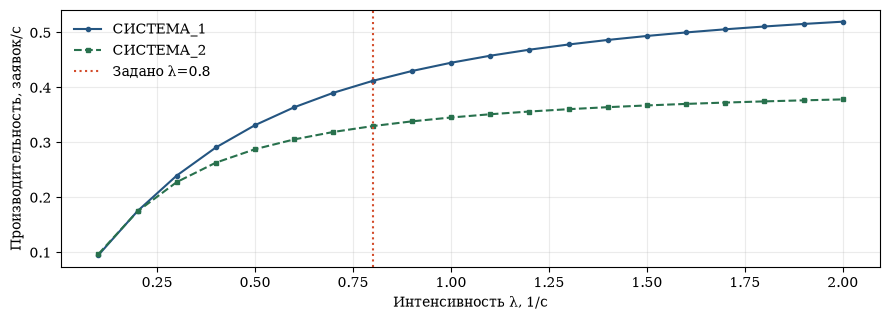

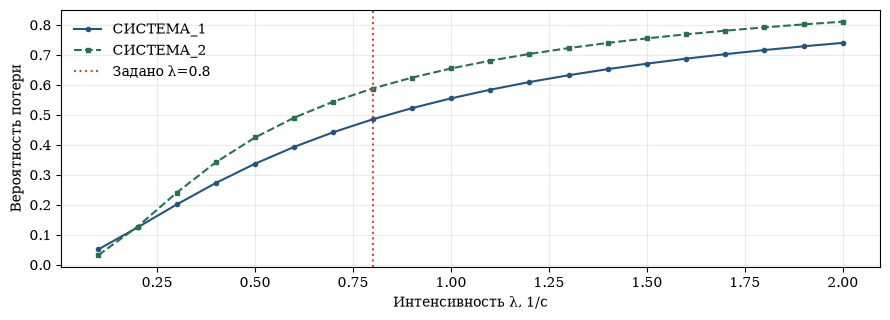

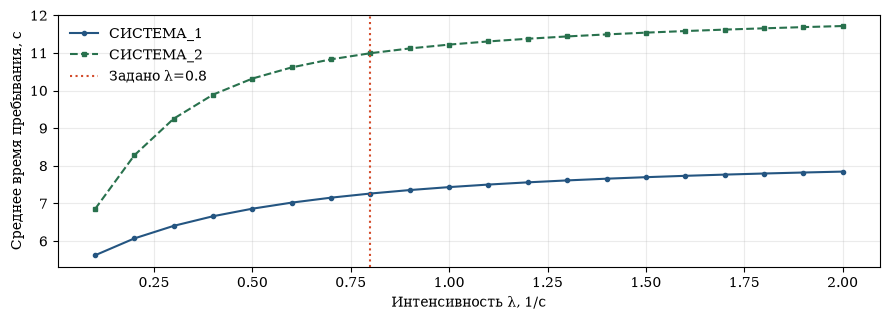

Точки сетки, где производительность второй выше: [0.1]
Вывод относится к исследованной сетке и заданной конфигурации очередей.


In [18]:
settings = [("Λ′1", "Λ′2", "Производительность, заявок/с"),
            ("π1", "π2", "Вероятность потери"), ("U1, с", "U2, с", "Среднее время пребывания, с")]
for key1, key2, ylabel in settings:
    fig, ax = plt.subplots()
    ax.plot(sweep["λ"], sweep[key1], "o-", color=BLUE, markersize=3, label="СИСТЕМА_1")
    ax.plot(sweep["λ"], sweep[key2], "s--", color=GREEN, markersize=3, label="СИСТЕМА_2")
    ax.axvline(BASE_LAMBDA, color=RED, linestyle=":", label=f"Задано λ={BASE_LAMBDA:g}")
    ax.set(xlabel="Интенсивность λ, 1/с", ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

second_better = sweep.loc[sweep["Λ′2"] > sweep["Λ′1"], "λ"].tolist()
print("Точки сетки, где производительность второй выше:", second_better)
print("Вывод относится к исследованной сетке и заданной конфигурации очередей.")

## 10. Сверка с расчётной книгой

Только теперь читается готовый Excel. Проверяем порядок состояний, обе полные
матрицы, вероятности, итоговые характеристики и все 20 точек трёх сравнительных
зависимостей. При изменении исходных параметров сверка со старой книгой пропускается.

In [19]:
candidates = [Path.cwd(), Path.cwd()/"Modeling"/"Lab2", Path.cwd()/"Lab2", Path.cwd().parent/"Lab2"]
LAB_DIR = next((folder for folder in candidates if (folder/"УИР_2_вариант_16_расчеты.xlsx").exists()), Path.cwd())
book_path = LAB_DIR / "УИР_2_вариант_16_расчеты.xlsx"
baseline = (BASE_LAMBDA == 0.8 and B == 5 and CV_H == 2.5 and
            np.array_equal(ALPHA1, [0.3, 0.45, 0.25]) and np.array_equal(ALPHA2, [0.3, 0.7]) and
            np.array_equal(CAPACITY1, [2, 2, 1]) and np.array_equal(CAPACITY2, [2, 3]))
if book_path.exists() and baseline:
    book = openpyxl.load_workbook(book_path, data_only=True)
    audit = []
    def compare(name, calculated, reference):
        calculated, reference = np.asarray(calculated, dtype=float), np.asarray(reference, dtype=float)
        np.testing.assert_allclose(calculated, reference, atol=1e-10, rtol=1e-10, err_msg=name)
        audit.append({"Проверка": name, "Макс. разница": np.max(abs(calculated-reference)), "Совпадает": True})

    for k, states, matrix, probabilities in [(1, states1, G1, p1), (2, states2, G2, p2)]:
        n = len(states)
        ws = book[f"СИСТЕМА_{k}"]
        assert [ws.cell(i+4, 2).value for i in range(n)] == [state_text(s) for s in states]
        compare(f"Вероятности системы {k}", probabilities, [ws.cell(i+4, 3).value for i in range(n)])
        ws = book[f"Матрица_Q{k}"]
        compare(f"Матрица системы {k}", matrix,
                [[ws.cell(i+4, j+2).value for j in range(n)] for i in range(n)])
    ws = book["Сравнение"]
    keys = ["utilization", "queue_length", "number_in_system", "wait_time", "sojourn_time", "loss_probability", "throughput"]
    for col, total in [(2, total1), (3, total2)]:
        compare(f"Итоговые характеристики системы {col-1}", [total[key] for key in keys],
                [ws.cell(row, col).value for row in range(4, 11)])
    compare("Варьирование: λ, производительность, потери, пребывание", sweep.iloc[:, :7].to_numpy(),
            [[ws.cell(row, col).value for col in range(1, 8)] for row in range(16, 36)])
    book.close()
    show_table(pd.DataFrame(audit).set_index("Проверка"), digits=12)
    print("Независимый расчёт Python совпал с Excel: обе матрицы, вероятности, характеристики и зависимости.")
else:
    print("Сверка пропущена: книга отсутствует или параметры изменены относительно исходного отчёта.")

| Проверка                                                |   Макс. разница | Совпадает   |
|:--------------------------------------------------------|----------------:|:------------|
| Вероятности системы 1                                   |  0.000000000000 | True        |
| Матрица системы 1                                       |  0.000000000000 | True        |
| Вероятности системы 2                                   |  0.000000000000 | True        |
| Матрица системы 2                                       |  0.000000000000 | True        |
| Итоговые характеристики системы 1                       |  0.000000000000 | True        |
| Итоговые характеристики системы 2                       |  0.000000000000 | True        |
| Варьирование: λ, производительность, потери, пребывание |  0.000000000000 | True        |

Независимый расчёт Python совпал с Excel: обе матрицы, вероятности, характеристики и зависимости.


## 11. Что выполнить вручную в MARK

1. Задать 18 или 20 состояний и ввести положительные внедиагональные переходы.
2. Рассчитать стационарные вероятности. В формулах MARK $E_1\leftrightarrow p0$,
   $E_2\leftrightarrow p1$ и так далее; диагональ рассчитывается автоматически.
3. Ввести формулы характеристик через вероятности и рассчитать их.
4. Выполнить варьирование, сохраняя одинаковые исходные параметры сравнения.
5. Сохранить настоящие `.mrk` и HTML-результаты программы и сверить их с Python.

Рядом в репозитории находятся [готовые входы для ручного ввода](../Preparation/winmark-input/READ_ME_FIRST.txt)
и [подробная инструкция подготовки](../Preparation/defense-guide.html#winmark).
Они рассчитаны для базовых параметров, перечисленных в разделе 1.
При изменении λ нужно пересчитывать все поступления и соответствующие формулы.

Этот notebook не управляет WinMark, не создаёт фиктивные `.mrk` и не подтверждает
выполнение этапа MARK. Для сдачи требование методички сохраняется.

## 12. Итог и короткий ответ на защите

In [20]:
display(Markdown(
    f"Построены модели на **{len(states1)} и {len(states2)} состояний**. "
    "Гиперэкспоненциальное обслуживание представлено выбором одной из двух экспоненциальных фаз. "
    "Матрицы сформированы из событий поступления и завершения обслуживания; стационарные "
    "вероятности найдены из баланса и нормировки. Характеристики рассчитаны через вероятности "
    "состояний, затем проверены по обслуженному потоку и формулам Литтла. "
    f"При λ={BASE_LAMBDA:g} производительность: **{total1['throughput']:.6f}** и "
    f"**{total2['throughput']:.6f}** заявки/с, поэтому выбрана **СИСТЕМА_{winner}**. "
    "Сравнение относится к очередям 1/1/0 и 1/2. Обязательный этап расчёта в MARK ещё предстоит."))

Построены модели на **18 и 20 состояний**. Гиперэкспоненциальное обслуживание представлено выбором одной из двух экспоненциальных фаз. Матрицы сформированы из событий поступления и завершения обслуживания; стационарные вероятности найдены из баланса и нормировки. Характеристики рассчитаны через вероятности состояний, затем проверены по обслуженному потоку и формулам Литтла. При λ=0.8 производительность: **0.411942** и **0.329662** заявки/с, поэтому выбрана **СИСТЕМА_1**. Сравнение относится к очередям 1/1/0 и 1/2. Обязательный этап расчёта в MARK ещё предстоит.

### Где смотреть в PDF и методичке

| Что показать | Актуальный PDF |
|---|---|
| Условия, критерий и сокращение очереди | 2–3 |
| Кодировка и фазы $H_{2.5}$ | 3 |
| Размеченные графы | 4–5 |
| Баланс и полные матрицы | 6–8 |
| Форма 1 | 9 |
| Формулы характеристик | 10 |
| Форма 2 | 11–12 |
| Проверка и сравнительные графики | 13–14 |

Источник условий: [методичка УИР 2](materials/Учебно-исследовательская%20работа%202%20(УИР%202)%20«Марковские%20модели%20систем%20массового%20обслуживания».pdf),
таблицы 1–2, с. 3 и 5–7. Требование MARK — п. 4.3, с. 1; прямой расчёт характеристик
и разрешение сокращать очередь — с. 7. Теория: `materials/МП_теория к УИР2.pdf`.
Сдаваемый отчёт: `3313_Якименко_Владислав_ЛР2.pdf`.